# 02 - Momentum walk-forward

**SYNTHETIC DATA.** Reads the outputs written by `scripts/run_walkforward.py` (re-running the search here would add duplicate trials to the trial registry) and recomputes the Deflated Sharpe Ratio from the trial log with package functions.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
from backtester import experiments as ex
from backtester.config import make_run_factory
from backtester.performance import compute_metrics, metrics_frame
from backtester.strategies import build_strategy

ctx = ex.Context(Path.cwd())   # finds the project folder from notebooks/
ex.ensure_datasets(ctx.root)
print('project:', ctx.root.name, '| hold-out starts', ctx.holdout_start.date(), '(never used here)')

project: backtester | hold-out starts 2022-01-01 (never used here)


In [2]:
trials = pd.read_csv(ctx.tables / 'momentum_wf_trial_log.csv')
print(len(trials), 'trials;', trials['status'].value_counts().to_dict())
trials.head()

112 trials; {'ok': 112}


,trial_id,experiment,fold,params,data_start,train_start,train_end,objective,sample,timestamp_utc,...,sharpe,sharpe_per_period,cagr,max_drawdown,n_obs,skew,kurtosis_pearson,n_round_trips,runtime_seconds,selected
0,1,momentum_wf,0,"{""lookback"": 126, ""quantile"": 0.1, ""skip"": 0}",2005-01-03,2005-01-03,2008-01-02,sharpe,training,2026-11-22T17:26:40+00:00,...,-0.689566,-0.043439,-0.128142,0.471457,782,-0.023436,4.003982,118,0.363,False
1,2,momentum_wf,0,"{""lookback"": 126, ""quantile"": 0.1, ""skip"": 21}",2005-01-03,2005-01-03,2008-01-02,sharpe,training,2026-11-22T17:26:41+00:00,...,-0.436139,-0.027474,-0.086803,0.449859,782,-0.260883,4.171456,118,0.078,False
2,3,momentum_wf,0,"{""lookback"": 126, ""quantile"": 0.2, ""skip"": 0}",2005-01-03,2005-01-03,2008-01-02,sharpe,training,2026-11-22T17:26:41+00:00,...,-0.668628,-0.042120,-0.107536,0.393756,782,-0.153175,4.143826,206,0.094,False
3,4,momentum_wf,0,"{""lookback"": 126, ""quantile"": 0.2, ""skip"": 21}",2005-01-03,2005-01-03,2008-01-02,sharpe,training,2026-11-22T17:26:41+00:00,...,-0.450555,-0.028382,-0.076370,0.376256,782,-0.075616,3.971818,206,0.091,False
4,5,momentum_wf,0,"{""lookback"": 252, ""quantile"": 0.1, ""skip"": 0}",2005-01-03,2005-01-03,2008-01-02,sharpe,training,2026-11-22T17:26:41+00:00,...,0.113063,0.007122,0.005406,0.184330,782,0.080255,4.591909,91,0.072,True


In [3]:
pd.read_csv(ctx.tables / 'momentum_wf_fold_summary.csv')

,fold,train_start,train_end,test_start,test_end,selected_params,train_objective,test_return,test_sharpe,test_max_drawdown,test_n_obs
0,0,2005-01-03,2008-01-02,2008-01-03,2009-01-02,"{""lookback"": 252, ""quantile"": 0.1, ""skip"": 0}",0.113063,0.069186,0.431820,0.162890,262
1,1,2006-01-03,2009-01-02,2009-01-05,2010-01-01,"{""lookback"": 252, ""quantile"": 0.2, ""skip"": 21}",0.791162,-0.086881,-0.446932,0.248231,260
2,2,2007-01-03,2010-01-01,2010-01-04,2010-12-31,"{""lookback"": 126, ""quantile"": 0.1, ""skip"": 21}",0.609647,0.000986,0.116031,0.140061,260
3,3,2008-01-03,2010-12-31,2011-01-03,2012-01-02,"{""lookback"": 126, ""quantile"": 0.1, ""skip"": 21}",0.230857,-0.250283,-1.165026,0.371883,261
4,4,2009-01-05,2012-01-02,2012-01-03,2013-01-02,"{""lookback"": 252, ""quantile"": 0.1, ""skip"": 21}",0.472203,-0.172880,-0.713279,0.304859,262
5,5,2010-01-04,2013-01-02,2013-01-03,2014-01-02,"{""lookback"": 252, ""quantile"": 0.1, ""skip"": 21}",0.428794,0.033811,0.255029,0.174054,261
6,6,2011-01-03,2014-01-02,2014-01-03,2015-01-02,"{""lookback"": 252, ""quantile"": 0.1, ""skip"": 21}",0.364364,0.250397,1.169748,0.150821,261
7,7,2012-01-03,2015-01-02,2015-01-05,2016-01-01,"{""lookback"": 252, ""quantile"": 0.2, ""skip"": 21}",0.460065,-0.160643,-0.745992,0.248945,260
8,8,2013-01-03,2016-01-01,2016-01-04,2017-01-02,"{""lookback"": 126, ""quantile"": 0.1, ""skip"": 21}",0.480401,0.027362,0.231599,0.126357,261
9,9,2014-01-03,2017-01-02,2017-01-03,2018-01-02,"{""lookback"": 126, ""quantile"": 0.1, ""skip"": 21}",0.615359,0.138699,0.652064,0.185841,261


## Deflated Sharpe Ratio

Per-fold DSR of the training selection against the fold's own trials (raw count and correlation-implied effective count), plus a conservative diagnostic for the stitched OOS track. DSR is not a probability of future profit.

In [4]:
pd.read_csv(ctx.tables / 'momentum_wf_deflated_sharpe.csv')

,scope,n_trials_basis,n_trials,avg_trial_corr,sr_annualised,sr0_annualised,dsr,psr_vs_zero,n_obs,warnings
0,fold 0 training selection,raw_attempted,8.000000,0.741174,0.113063,0.503528,0.245859,0.578906,782,NaN
1,fold 0 training selection,implied_independent,2.811782,0.741174,0.113063,0.277603,0.386007,0.578906,782,NaN
2,fold 1 training selection,raw_attempted,8.000000,0.785242,0.791162,0.400302,0.754538,0.918390,784,NaN
3,fold 1 training selection,implied_independent,2.503308,0.785242,0.791162,0.195765,0.852983,0.918390,784,NaN
4,fold 2 training selection,raw_attempted,8.000000,0.793015,0.609647,0.222229,0.752757,0.858830,783,NaN
5,fold 2 training selection,implied_independent,2.448898,0.793015,0.609647,0.105965,0.812788,0.858830,783,NaN
6,fold 3 training selection,raw_attempted,8.000000,0.808263,0.230857,0.176379,0.538227,0.657875,782,NaN
7,fold 3 training selection,implied_independent,2.342160,0.808263,0.230857,0.079649,0.605021,0.657875,782,NaN
8,fold 4 training selection,raw_attempted,8.000000,0.807858,0.472203,0.416085,0.539359,0.797157,781,NaN
9,fold 4 training selection,implied_independent,2.344997,0.807858,0.472203,0.188184,0.691509,0.797157,781,NaN


In [5]:
from backtester.statistics import deflated_sharpe_ratio
f0 = trials[(trials.fold == 0) & (trials.status == 'ok')]
sel = f0[f0.selected].iloc[0]
deflated_sharpe_ratio(sel['sharpe_per_period'], f0['sharpe_per_period'].tolist(), int(sel['n_obs']),
                      sel['skew'], sel['kurtosis_pearson'], n_trials=len(trials[trials.fold == 0]))

{'sr_per_period': np.float64(0.007122281077283057),
 'n_obs': 782,
 'n_trials': 8.0,
 'skew': np.float64(0.08025478174471572),
 'kurtosis_pearson': np.float64(4.591909180486678),
 'warnings': [],
 'var_trial_sr': 0.00047263708544511163,
 'sr0_per_period': np.float64(0.031719284335409034),
 'dsr': 0.24585928180892086,
 'psr_vs_zero': 0.5789055205678962}

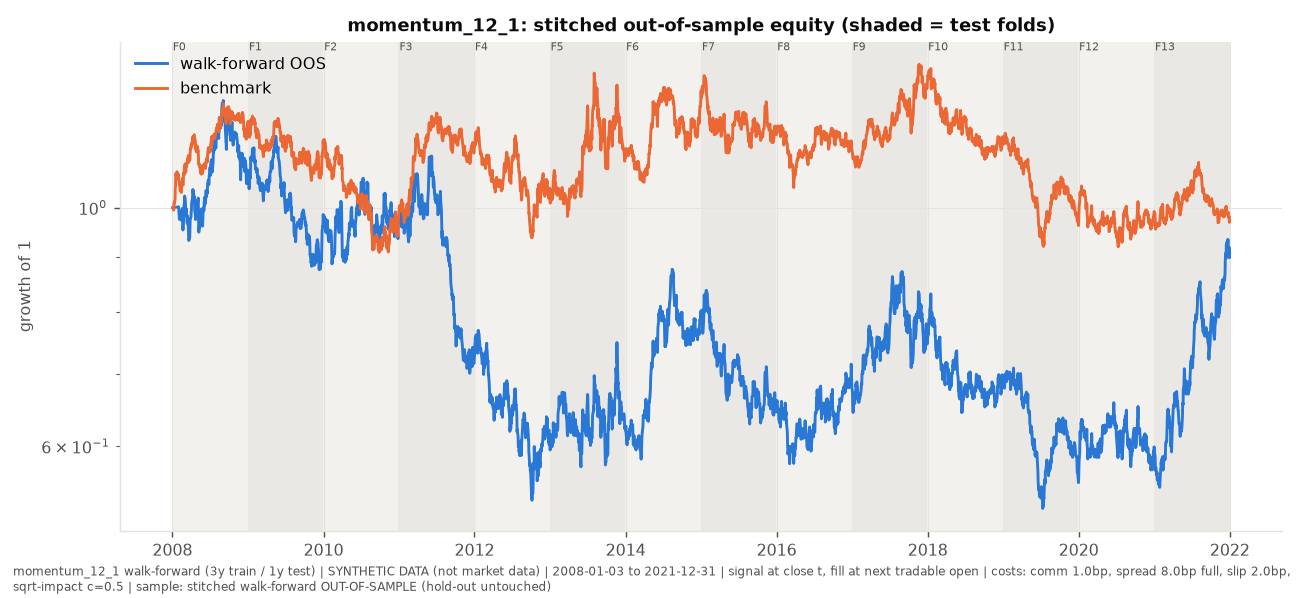

In [6]:
display(Image(filename=str(ctx.figs / '06_momentum_wf_stitched_oos_equity.png'), width=900))

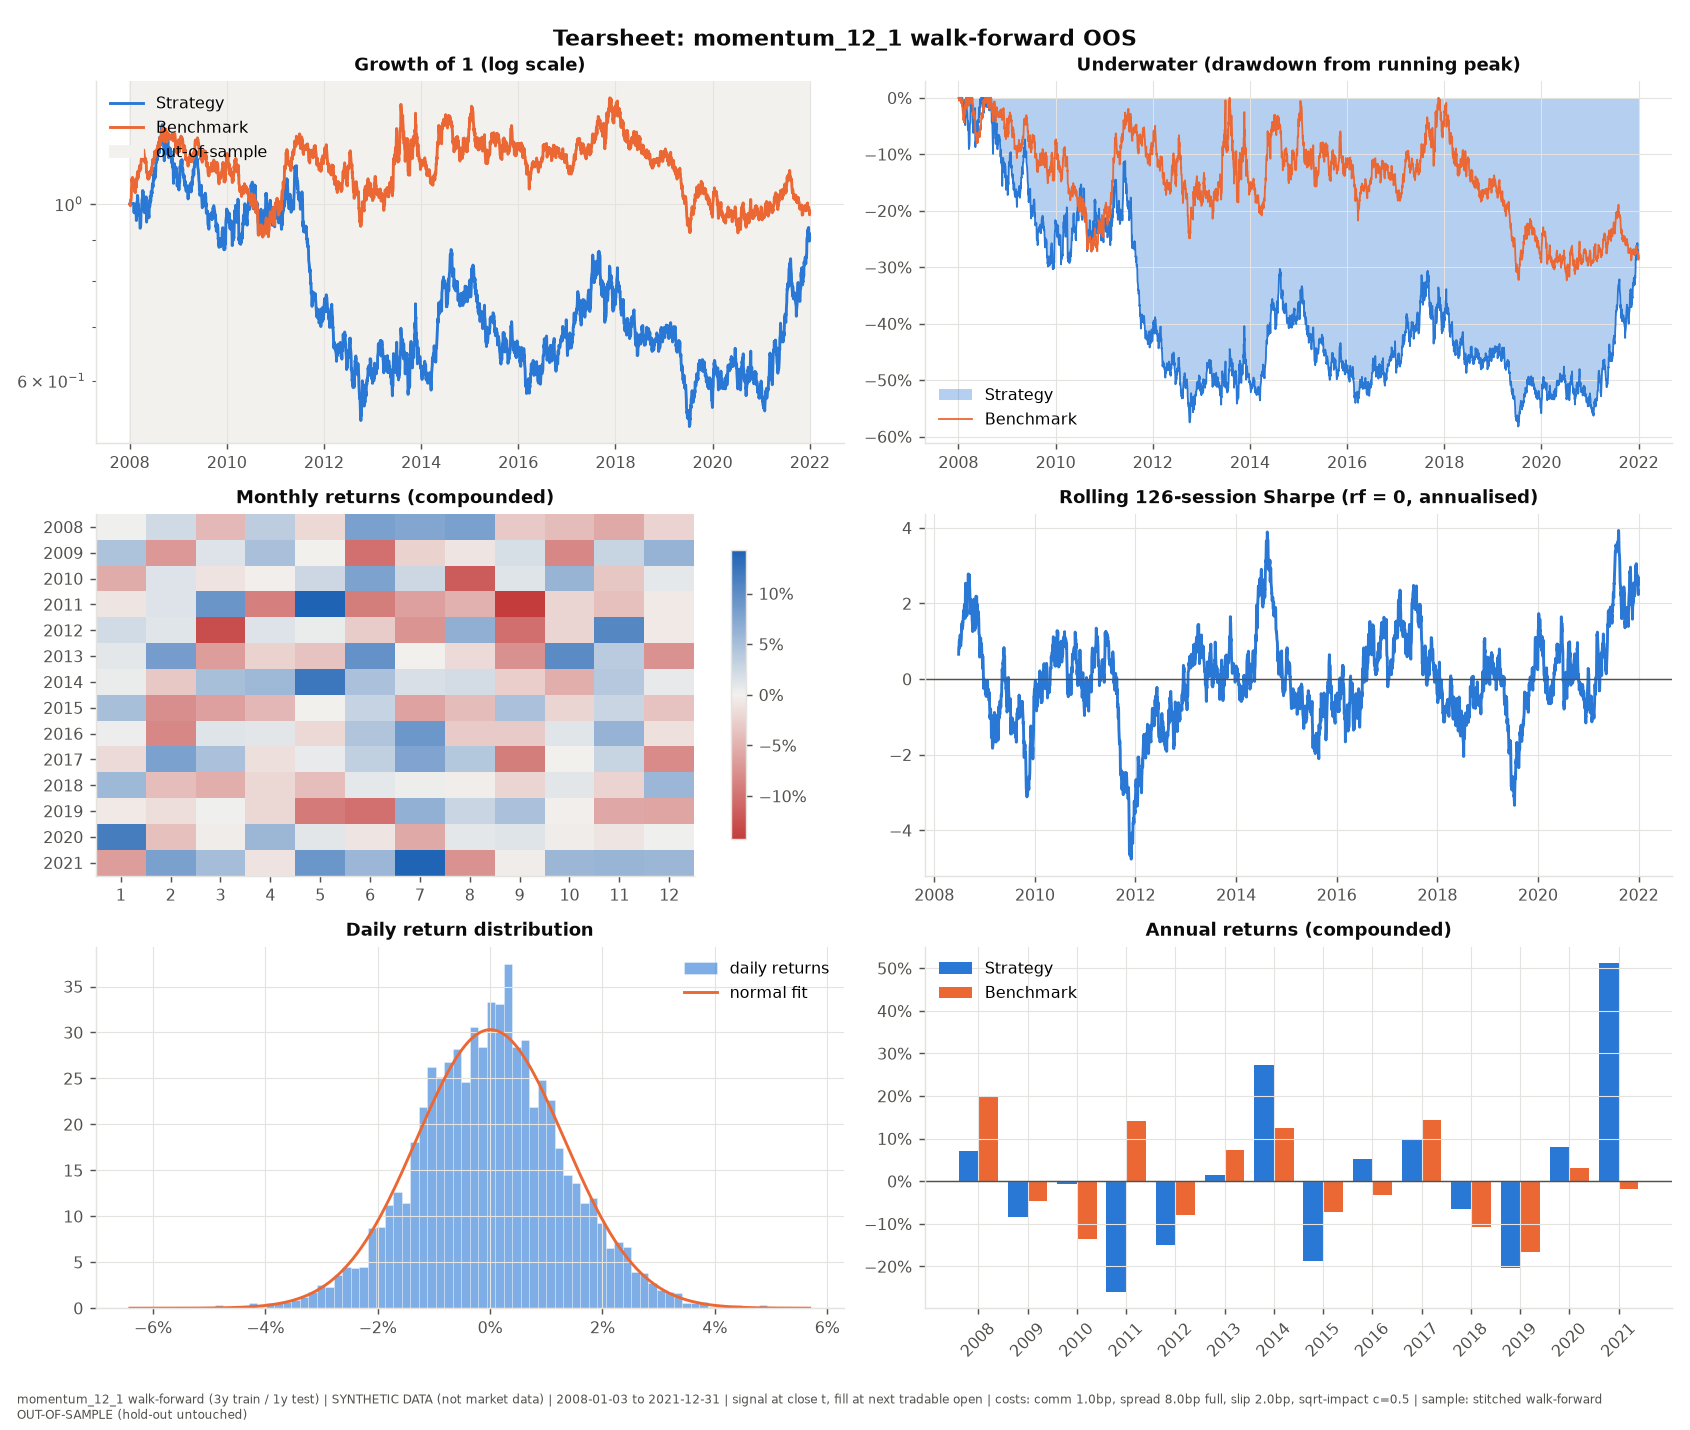

In [7]:
display(Image(filename=str(ctx.figs / '06_momentum_wf_oos_tearsheet.png'), width=900))